In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv('/content/spotify dataset.csv')

print("Dataset Shape:", df.shape)
print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (32833, 23)

First 5 Records:


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  32833 non-null  object 
 1   track_name                32828 non-null  object 
 2   track_artist              32828 non-null  object 
 3   track_popularity          32833 non-null  int64  
 4   track_album_id            32833 non-null  object 
 5   track_album_name          32828 non-null  object 
 6   track_album_release_date  32833 non-null  object 
 7   playlist_name             32833 non-null  object 
 8   playlist_id               32833 non-null  object 
 9   playlist_genre            32833 non-null  object 
 10  playlist_subgenre         32833 non-null  object 
 11  danceability              32833 non-null  float64
 12  energy                    32833 non-null  float64
 13  key                       32833 non-nul

,track_popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
count,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000
mean,42.477081,0.654850,0.698619,5.374471,-6.719499,0.565711,0.107068,0.175334,0.084747,0.190176,0.510561,120.881132,225799.811622
std,24.984074,0.145085,0.180910,3.611657,2.988436,0.495671,0.101314,0.219633,0.224230,0.154317,0.233146,26.903624,59834.006182
min,0.000000,0.000000,0.000175,0.000000,-46.448000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4000.000000
25%,24.000000,0.563000,0.581000,2.000000,-8.171000,0.000000,0.041000,0.015100,0.000000,0.092700,0.331000,99.960000,187819.000000
50%,45.000000,0.672000,0.721000,6.000000,-6.166000,1.000000,0.062500,0.080400,0.000016,0.127000,0.512000,121.984000,216000.000000
75%,62.000000,0.761000,0.840000,9.000000,-4.645000,1.000000,0.132000,0.255000,0.004830,0.248000,0.693000,133.918000,253585.000000
max,100.000000,0.983000,1.000000,11.000000,1.275000,1.000000,0.918000,0.994000,0.994000,0.996000,0.991000,239.440000,517810.000000


In [4]:
print("Missing values:")
print(df.isnull().sum())

print("Duplicate records:", df.duplicated().sum())

df = df.drop_duplicates()

df['track_album_release_date'] = pd.to_datetime(
    df['track_album_release_date'],
    errors='coerce'
)

df = df.dropna(
    subset=['playlist_genre', 'playlist_name',
            'track_name', 'track_artist']
)

print("Cleaned Dataset Shape:", df.shape)

Missing values:
track_id                    0
track_name                  5
track_artist                5
track_popularity            0
track_album_id              0
track_album_name            5
track_album_release_date    0
playlist_name               0
playlist_id                 0
playlist_genre              0
playlist_subgenre           0
danceability                0
energy                      0
key                         0
loudness                    0
mode                        0
speechiness                 0
acousticness                0
instrumentalness            0
liveness                    0
valence                     0
tempo                       0
duration_ms                 0
dtype: int64
Duplicate records: 0
Cleaned Dataset Shape: (32828, 23)


In [6]:
features = [
    'track_popularity',
    'danceability',
    'energy',
    'key',
    'loudness',
    'mode',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo',
    'duration_ms'
]

df[features] = df[features].apply(
    pd.to_numeric, errors='coerce'
)

df = df.dropna(subset=features)

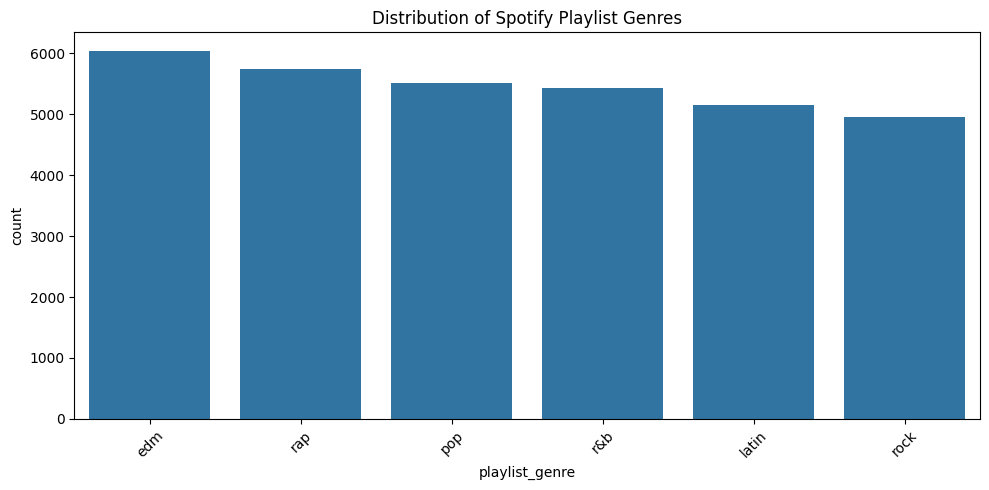

In [7]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x='playlist_genre',
    order=df['playlist_genre'].value_counts().index
)

plt.title("Distribution of Spotify Playlist Genres")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

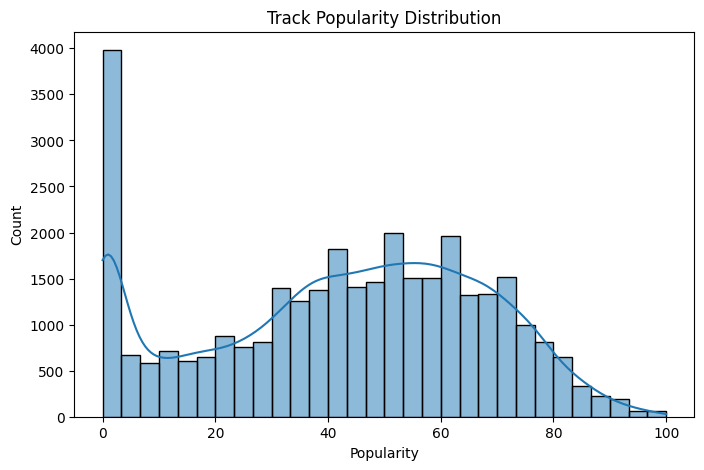

In [8]:
plt.figure(figsize=(8,5))

sns.histplot(df['track_popularity'], bins=30, kde=True)

plt.title("Track Popularity Distribution")
plt.xlabel("Popularity")
plt.show()

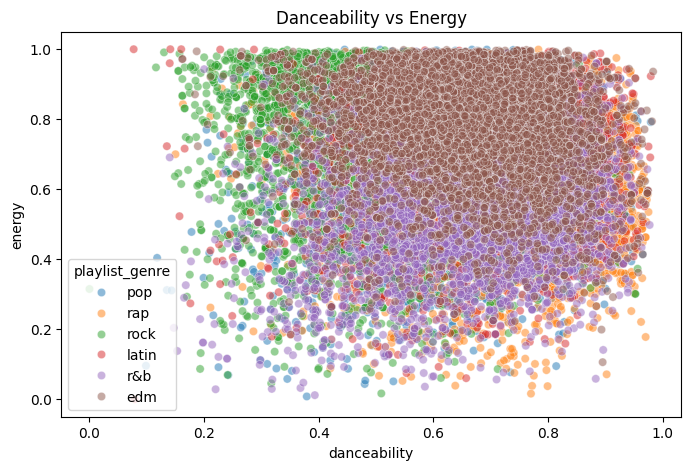

In [9]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='danceability',
    y='energy',
    hue='playlist_genre',
    alpha=0.5
)

plt.title("Danceability vs Energy")
plt.show()

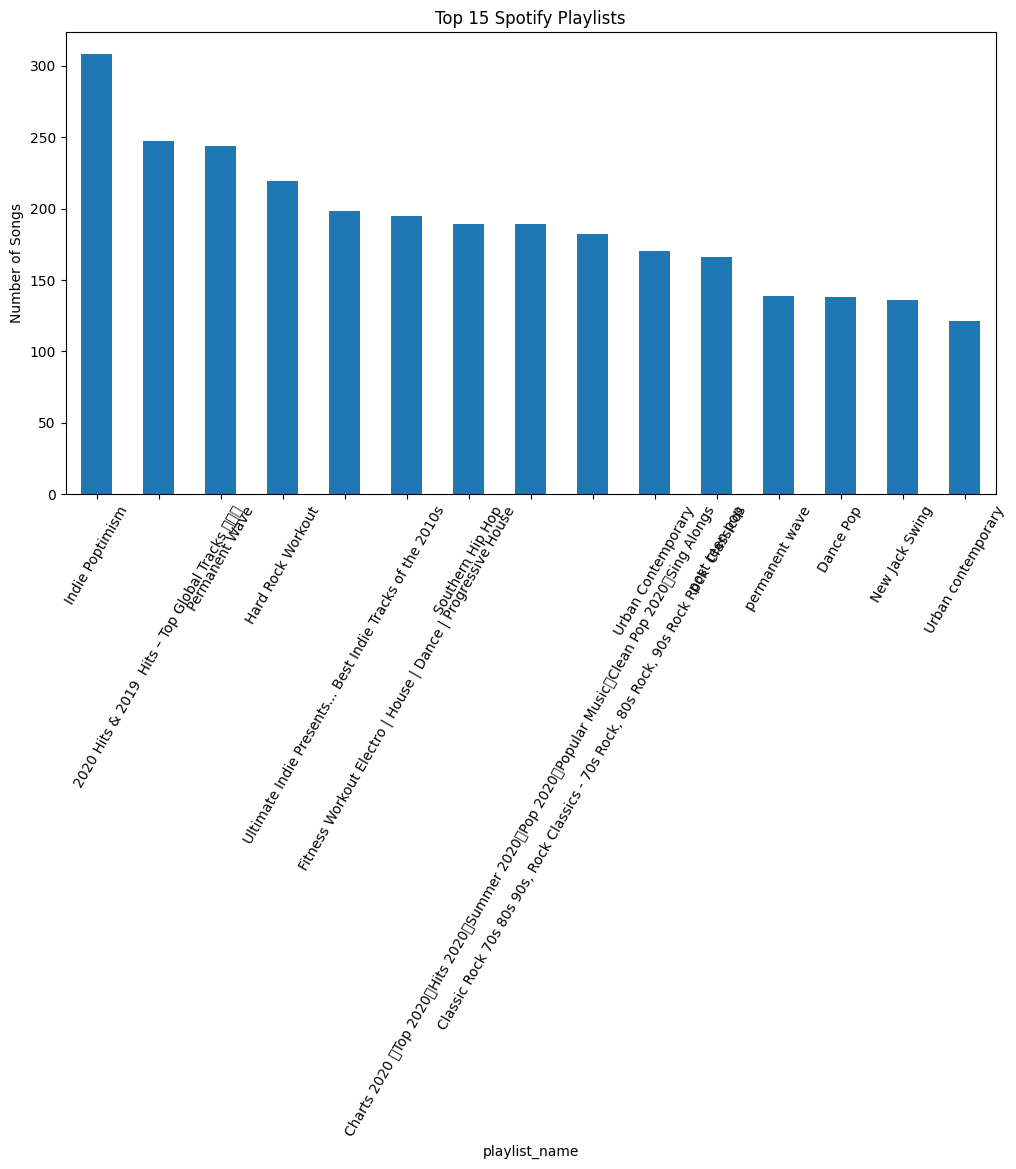

In [10]:
plt.figure(figsize=(12,6))

df['playlist_name'].value_counts().head(15).plot(
    kind='bar'
)

plt.title("Top 15 Spotify Playlists")
plt.ylabel("Number of Songs")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

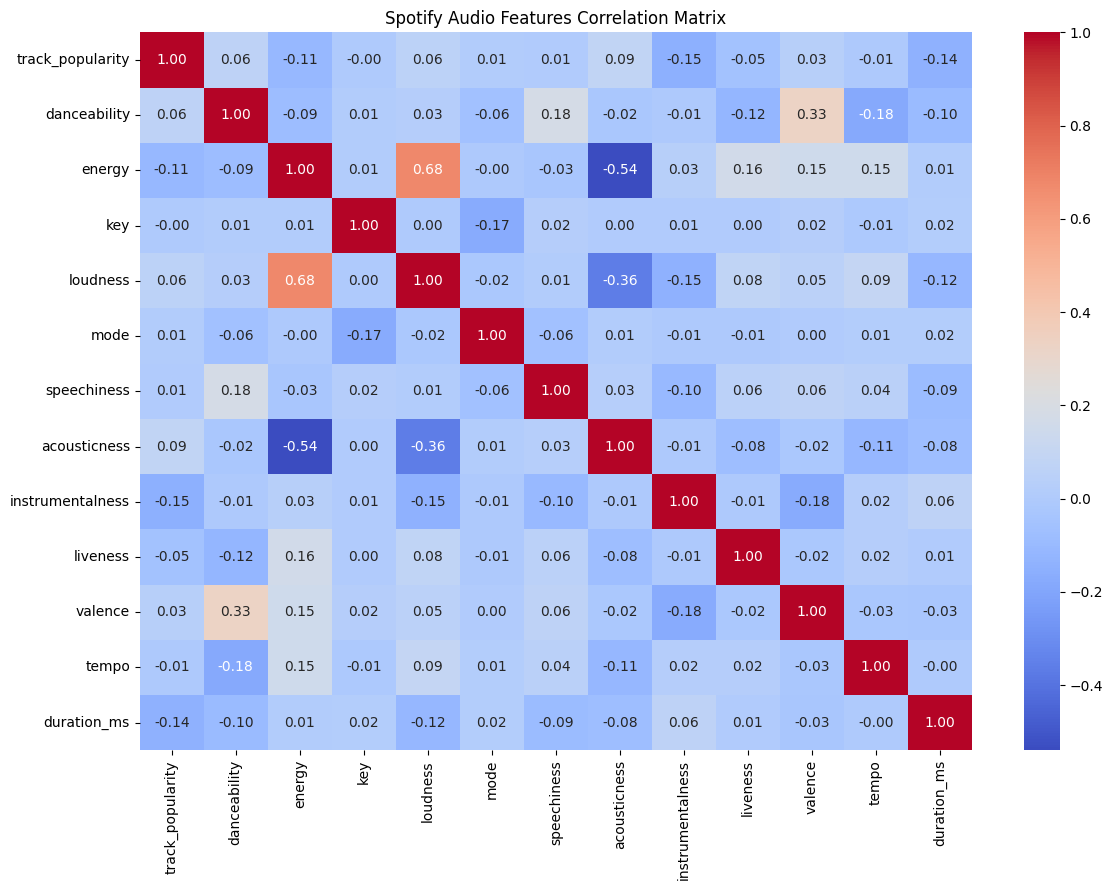

In [11]:
plt.figure(figsize=(12,9))

correlation = df[features].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Spotify Audio Features Correlation Matrix")
plt.tight_layout()
plt.show()

In [12]:
scaler = StandardScaler()

X = scaler.fit_transform(df[features])

print("Feature scaling completed!")

Feature scaling completed!


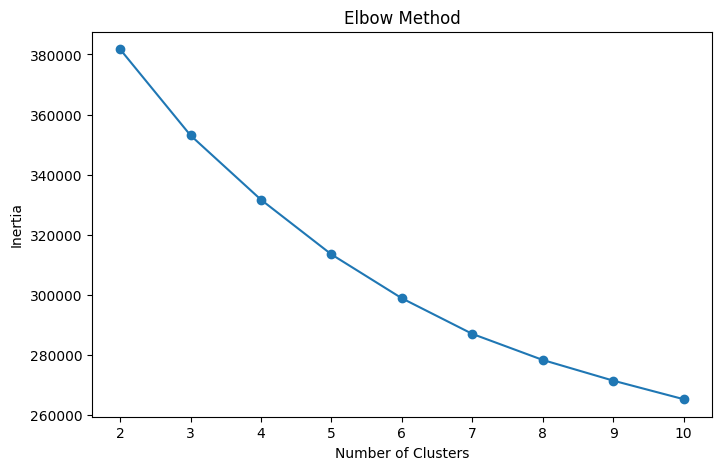

In [13]:
sse = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X)

    sse.append(model.inertia_)

plt.figure(figsize=(8,5))

plt.plot(range(2,11), sse, marker='o')

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")

plt.show()

In [14]:
kmeans = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

df['cluster'] = kmeans.fit_predict(X)

print(df[['track_name',
          'playlist_genre',
          'cluster']].head(10))

                                          track_name playlist_genre  cluster
0  I Don't Care (with Justin Bieber) - Loud Luxur...            pop        0
1                    Memories - Dillon Francis Remix            pop        0
2                    All the Time - Don Diablo Remix            pop        3
3                  Call You Mine - Keanu Silva Remix            pop        0
4            Someone You Loved - Future Humans Remix            pop        0
5  Beautiful People (feat. Khalid) - Jack Wins Remix            pop        0
6                    Never Really Over - R3HAB Remix            pop        4
7           Post Malone (feat. RANI) - GATTÜSO Remix            pop        4
8             Tough Love - Tiësto Remix / Radio Edit            pop        4
9                If I Can't Have You - Gryffin Remix            pop        0


In [15]:
score = silhouette_score(
    X,
    df['cluster'],
    sample_size=min(5000, len(df)),
    random_state=42
)

print("Silhouette Score:", score)

Silhouette Score: 0.08977966639382398


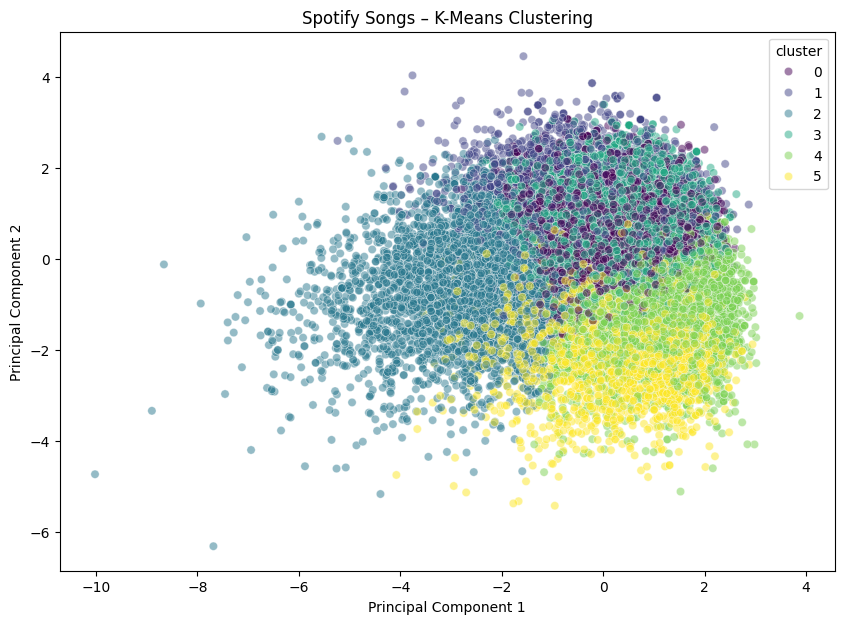

In [16]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

plt.figure(figsize=(10,7))

sns.scatterplot(
    x=X_pca[:,0],
    y=X_pca[:,1],
    hue=df['cluster'],
    palette='viridis',
    alpha=0.5
)

plt.title("Spotify Songs – K-Means Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

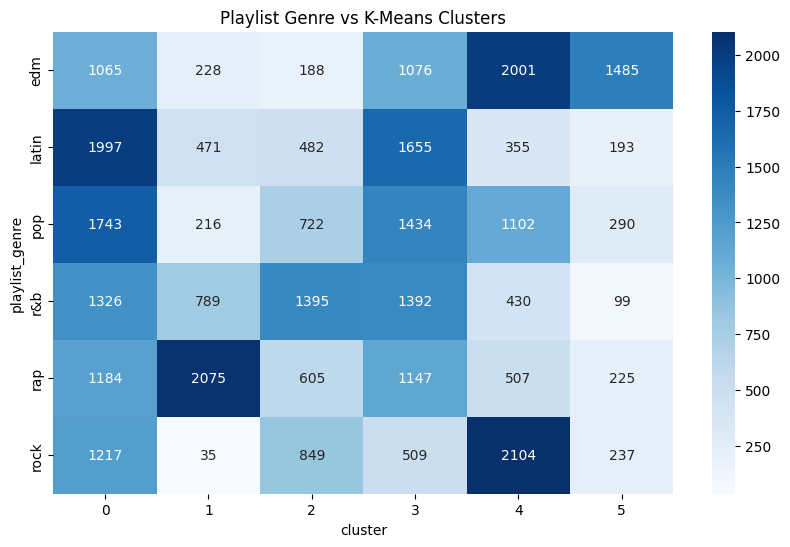

In [17]:
genre_cluster = pd.crosstab(
    df['playlist_genre'],
    df['cluster']
)

plt.figure(figsize=(10,6))

sns.heatmap(
    genre_cluster,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Playlist Genre vs K-Means Clusters")
plt.show()

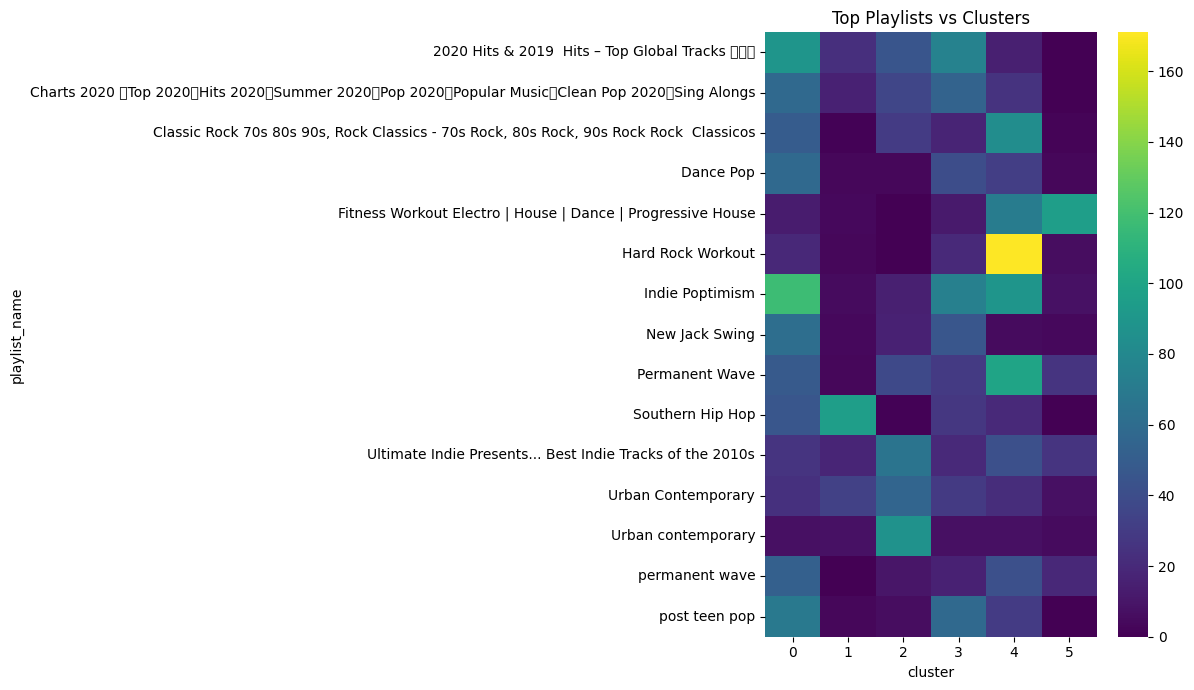

In [18]:
playlist_cluster = pd.crosstab(
    df['playlist_name'],
    df['cluster']
)

top_playlists = df['playlist_name'].value_counts().head(15).index

plt.figure(figsize=(12,7))

sns.heatmap(
    playlist_cluster.loc[
        playlist_cluster.index.intersection(top_playlists)
    ],
    cmap='viridis'
)

plt.title("Top Playlists vs Clusters")
plt.tight_layout()
plt.show()

,track_popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
cluster,,,,,,,,,,,,,
0,47.441983,0.715800,0.727088,4.595992,-6.141904,1.000000,0.076912,0.132142,0.013581,0.161076,0.622976,115.925222,218957.647211
1,42.511536,0.714496,0.657520,5.619035,-7.029891,0.508915,0.331216,0.189852,0.011636,0.206295,0.546455,123.775380,217920.051652
2,44.151851,0.592405,0.414059,5.200660,-10.696761,0.630512,0.072281,0.545761,0.102460,0.156504,0.385570,112.622069,226131.978779
3,46.674615,0.720493,0.720022,6.326217,-6.106482,0.000000,0.083855,0.142354,0.016359,0.165546,0.601856,115.767029,220579.557050
4,35.555624,0.505121,0.812870,5.314356,-5.296280,0.615018,0.077234,0.059665,0.029390,0.268743,0.370890,135.035826,234668.679181
5,28.765520,0.661547,0.786891,5.356663,-6.936511,0.564650,0.071787,0.069502,0.742868,0.188848,0.385257,125.329887,252268.403321


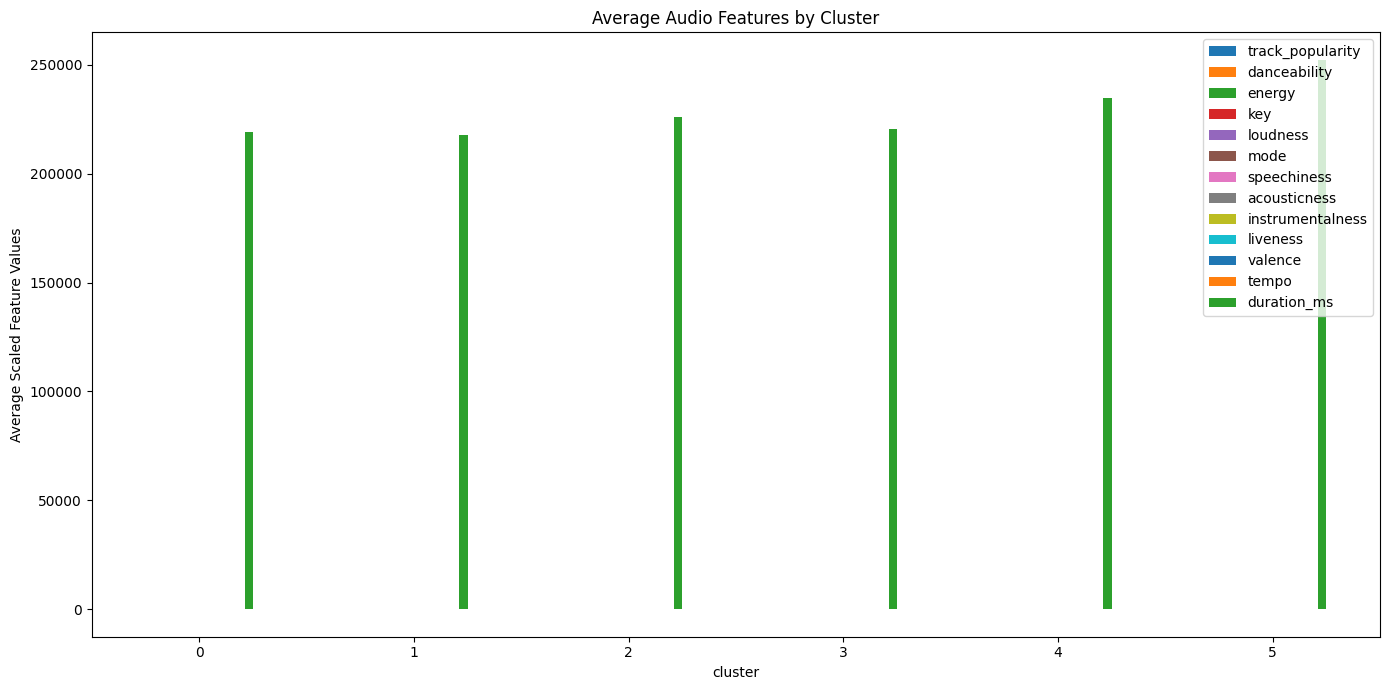

In [19]:
cluster_means = df.groupby('cluster')[features].mean()

display(cluster_means)

cluster_means.plot(
    kind='bar',
    figsize=(14,7)
)

plt.title("Average Audio Features by Cluster")
plt.ylabel("Average Scaled Feature Values")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [20]:
def recommend_songs(song_name, top_n=5):

    matches = df[
        df['track_name'].str.lower() ==
        song_name.lower()
    ]

    if matches.empty:
        print("Song not found!")
        return

    selected = matches.iloc[0]

    recommendations = df[
        (df['cluster'] == selected['cluster']) &
        (df['track_id'] != selected['track_id'])
    ]

    recommendations = recommendations.sort_values(
        by='track_popularity',
        ascending=False
    )

    return recommendations[
        ['track_name', 'track_artist',
         'playlist_genre', 'track_popularity']
    ].head(top_n)


display(recommend_songs("Memories"))

,track_name,track_artist,playlist_genre,track_popularity
21564,everything i wanted,Billie Eilish,r&b,97
5261,everything i wanted,Billie Eilish,pop,97
30210,everything i wanted,Billie Eilish,edm,97
1548,everything i wanted,Billie Eilish,pop,97
22940,everything i wanted,Billie Eilish,r&b,97
